<a href="https://colab.research.google.com/github/jess22jess/SIMULACI-N-II/blob/main/Ejemplo_en_clase_del_mov_brown_con_deriva.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Arcos Gutiérrez Jessica Beatriz**

---

*Ejemplo.* Encuentre la probabilidad de que el MB con parámetro $\mu$ = 0.6 y $\sigma=0.5$, tome valores entre 1 y 3 al tiempo t=4.

---
donde $$X_t=0.6t+0.5B_t$$

Sustituyendo t=4:

$$P(1<X_4<3)=P(1<2.4+\frac{1}{2}B_4<3)$$
$$=P(-1.4<\frac{1}{2}B_4<0.6)$$
$$=P(-2.8<B_4<1.2)$$
$$=\int_{-2.8}^{1.2} \frac{1}{\sqrt{2*4*π}}e^{-\frac{x^2}{8}}dx$$

$$=0.645$$

**Nota:** La varianza de $B_t$ es t

---

Por lo tanto, la probabilidad de que $B_4$ este entre 1 Y 3 es de 0.645

In [43]:
import numpy as np
import random as r
import matplotlib.pyplot as plt
from scipy import stats

# Integral de la solución analítica:

Límites

In [44]:
limite_inferior = -2.8
limite_superior = 1.2

In [46]:
probab_int = stats.norm.cdf(limite_superior, loc=0, scale=2) - stats.norm.cdf(limite_inferior, loc=0, scale=2)

In [47]:
probab_int

np.float64(0.6449902230161554)

Que basicamente es 0.645

---

# Solución simulada:

Tomamos el programa del movimiento browniano y lo adecuamos al ejercicio

In [45]:
def deriva(T, n, mu, sigma):
    lista = []
    dt = T / n
    salto = np.sqrt(dt)
    B_0 = 0
    for i in range(1, n + 1):
        Z = r.gauss(0, 1)
        B_1 = B_0 + salto * Z
        t_0 = i * dt
        X_t = mu * t_0 + sigma * B_1  #X_t = mu * t + sigma * B_t

        lista.append(X_t)
        B_0 = B_1
    return lista

Simulaciones totales

In [23]:
N=10000

Caminatas dentro del intervalo [1,3]

In [24]:
M=0

In [25]:
for _ in range(N):
    trayectoria = deriva(4, 100, 0.6, 0.5)
    X_final = trayectoria[-1]
    if 1 <= X_final <= 3:   # aquí checamos si cae en entre 1 y 3
        M += 1

Calculamos la probabilidad de que caiga en el intervalo

In [26]:
probabilidad = M / N

In [27]:
probabilidad

0.6434

Recordemos que el resultado analítico es 0.645

---

Con el puente Browniano:

In [32]:
M_puente = 0

In [33]:
for _ in range(N):
    trayectoria = deriva(4, 100, 0.6, 0.5)
    puente = [x_t - (i / 100) * trayectoria[-1] for i, x_t in enumerate(trayectoria)]
    X_fin = puente[-1]

    if 1 <= X_fin <= 3:
        M_puente += 1

In [35]:

prob_puente = M_puente / N

In [36]:
prob_puente

0.0

# Graficamos para comparar:

In [39]:
tiempos = [i * (4 / 100) for i in range(1, 101)]

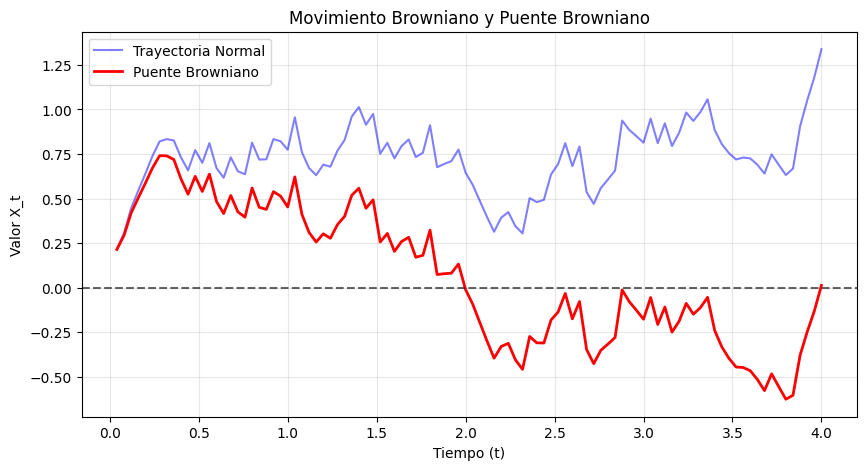

In [41]:
plt.figure(figsize=(10, 5))
plt.plot(tiempos, trayectoria, label="Trayectoria Normal", color='blue', alpha=0.5) # Trayectoria original
plt.plot(tiempos, puente, label="Puente Browniano", color='red', linewidth=2) # Puente Browniano
plt.axhline(0, color='black', linestyle='--', alpha=0.6)
plt.title("Movimiento Browniano y Puente Browniano")
plt.xlabel("Tiempo (t)")
plt.ylabel("Valor X_t")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()